# 09 · CDI-domain cluster strength, any datasets

**What it does.** Per CDI domain, Δ = mean between-domain distance − mean within-domain distance, for any 2+ of
`bv vedb things imagenet lvis` on their shared categories.

**Decisions** (see `../README.md`, review notes)
- **Two scales.** Raw cosine distance (manuscript notebook 05) and **Δ divided by the SD of that RDM's distances**.
  RDMs differ a lot in spread (ImageNet and THINGS are compressed), which shrinks raw Δ regardless of structure;
  compare datasets on the scaled version.
- **Is there structure?** One domain-label shuffle per draw applied to every RDM (2,000); ribbons = 2.5–97.5%.
- **Does one dataset cluster more than another?** **Within-domain category bootstrap** (2,000), two-sided, BH-FDR
  across domains. A shuffle null cannot answer this: it removes structure from both datasets at once.
- Domains with **< 5 categories are not tested**: resampling 2–3 categories says nothing about variability.
- The fast Δ is checked against notebook 05's reference implementation (`cluster_within_between`, copied below).

**Outputs:** `outputs/cluster_strength/<datasets>/results/` and `figures/` (raw and `_sdnorm`).

In [1]:
# Standard setup shared by every notebook (each notebook is self-contained).
import json
import os
import random
import re
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch, Rectangle
from scipy.cluster.hierarchy import leaves_list, linkage, optimal_leaf_ordering
from scipy.spatial.distance import pdist, squareform
from scipy.stats import false_discovery_control, pearsonr, rankdata, spearmanr, wilcoxon
from IPython.display import Image, Markdown, display

plt.rcParams["font.family"] = ["DejaVu Sans", "sans-serif"]
pd.set_option("display.max_colwidth", 120)


def show_images(paths, width=950):
    """Display saved figures (the files this notebook writes)."""
    for p in map(Path, paths):
        if p.exists():
            display(Markdown(f"`{p.relative_to(ROOT)}`")); display(Image(filename=str(p), width=width))
        else:
            display(Markdown(f"*Missing figure:* `{p}`"))

In [2]:
# Paths. Run this notebook from analysis/comparison-datasets/notebooks/ (Jupyter's default working directory).
ROOT = Path.cwd().resolve().parent                     # analysis/comparison-datasets
assert (ROOT / "notebooks").is_dir(), "open this notebook from analysis/comparison-datasets/notebooks/"
REPO = ROOT.parents[1]
DATA_DIR = REPO / "data"
MANUSCRIPT_DIR = REPO / "analysis" / "manuscript-2026"
VEDB_DIR = REPO / "analysis" / "vedb-1612"
VOCAB_DIR = DATA_DIR / "vocabulary_lists"
VALID129_TXT = VOCAB_DIR / "included_categories_valid129.txt"

# Inputs written by other pipelines (read only).
EXEMPLAR_EMBED_ROOT = Path(os.environ.get("BV_EXEMPLAR_EMBED_ROOT",
                                          str(MANUSCRIPT_DIR / "exemplar_set_embeddings"))).expanduser()
BV_THINGS_VALID129 = EXEMPLAR_EMBED_ROOT / "valid129"       # manuscript Stage 0: BV + THINGS tables
VEDB_VALID129 = VEDB_DIR / "exemplar_set_embeddings" / "valid129"   # vedb-1612 Stage 0 (files use the "bv_" prefix)

# External data on ccn2.
IMAGENET_DIR = Path("/data2/j7yang/imagenet-1k/extracted")
IMAGENET_EMBED_ROOT = Path("/ccn2a/dataset/babyview/related_data/imagenet_1k/outputs/image_embeddings")
LVIS_ROOT = Path("/data2/j7yang/lvis")
LVIS_CROP_EMBED_ROOT = Path("/ccn2a/dataset/babyview/related_data/lvis/outputs/crop_embeddings")

# Outputs of this folder.
OUT = ROOT / "outputs"
MAPPING_OUT = OUT / "mapping"
MONTAGE_OUT = OUT / "montages"
EXEMPLAR_SETS = OUT / "exemplar_sets"
MODELS = ("clip", "dinov3")

## Parameters

In [3]:
DATASETS = ["bv", "vedb", "things", "lvis"]
N_PERM, N_BOOT = 2000, 2000

_allowed = ('bv', 'vedb', 'things', 'imagenet', 'lvis')
assert set(DATASETS) <= set(_allowed) and len(set(DATASETS)) >= 2, f"DATASETS must be 2+ of {_allowed}"
DATASETS = [d for d in _allowed if d in DATASETS]   # fixed display order

## Shared helpers

In [4]:
def load_cdi_semantic_map() -> dict[str, str]:
    """``uni_lemma`` → CDI semantic domain from ``data/cdi_words.csv``.

    Frequency tables under ``data/long_tailed_dist_prop_included_categories_*.csv``
    are not a semantic source: the unfiltered valid129 file currently copies
    valid85 labels and marks the extra 44 categories as ``other``.
    """
    import pandas as pd

    path = DATA_DIR / "cdi_words.csv"
    df = pd.read_csv(path, usecols=["uni_lemma", "category"])
    df["uni_lemma"] = df["uni_lemma"].astype(str).str.strip().str.lower()
    df["category"] = df["category"].astype(str).str.strip().str.lower()
    return (
        df.drop_duplicates(subset=["uni_lemma"], keep="first")
        .set_index("uni_lemma")["category"]
        .to_dict()
    )


# Dataset registry and raw-table loading (shared helpers; repeated in each notebook that needs them).
ALL_DATASETS = ("bv", "vedb", "things", "imagenet", "lvis")
LABEL = {"bv": "BV", "vedb": "VEDB", "things": "THINGS", "imagenet": "ImageNet", "lvis": "LVIS"}
COLOR = {"bv": "#90caf9", "vedb": "#0d47a1", "imagenet": "#eb6834", "lvis": "#1baf7a", "things": "#eda100"}
COMPARISON_SETS = {"imagenet": "imagenet_exclusive75", "lvis": "lvis_exclusive104"}


def zscore_rows(X: np.ndarray, eps: float = 1e-10) -> np.ndarray:
    """Same as manuscript notebook 07: z-score each dimension across categories."""
    return (X - X.mean(axis=0)) / (X.std(axis=0) + eps)


def raw_path(ds: str, model: str) -> Path:
    if ds in COMPARISON_SETS:
        s = COMPARISON_SETS[ds]
        return EXEMPLAR_SETS / s / f"{ds}_{model}_exemplar_avg_raw_within_{s}.csv"
    if ds == "vedb":
        return VEDB_VALID129 / f"bv_{model}_exemplar_avg_raw_within_valid129.csv"
    return BV_THINGS_VALID129 / f"{ds}_{model}_exemplar_avg_raw_within_valid129.csv"


def load_raw(path: Path, cats: list[str]) -> np.ndarray:
    df = pd.read_csv(path)
    df["category"] = df["category"].astype(str).str.strip().str.lower()
    return df.set_index("category").loc[cats].filter(like="dim_").to_numpy(dtype=np.float64)


def shared_categories(datasets) -> list[str]:
    """Categories present in every given dataset's table, for both models (sorted)."""
    present = None
    for ds in datasets:
        for model in MODELS:
            cats = set(pd.read_csv(raw_path(ds, model), usecols=["category"])["category"].str.strip().str.lower())
            present = cats if present is None else present & cats
    return sorted(present)


def zscored_tables(datasets, cats, model) -> dict[str, np.ndarray]:
    """{dataset: category x dim matrix}, each z-scored within cats."""
    return {ds: zscore_rows(load_raw(raw_path(ds, model), cats)) for ds in datasets}

## Reference Δ and shuffle helpers (from manuscript notebook 05 / vedb-1612)

In [5]:
def cluster_within_between(categories, semantics, rdm):
    import numpy as np
    import pandas as pd

    sem_to_idx = defaultdict(list)
    for i, sem in enumerate(semantics):
        sem_to_idx[sem].append(i)
    rows = []
    n = len(categories)
    all_idx = np.arange(n)
    for sem, idx_list in sorted(sem_to_idx.items()):
        idx = np.array(idx_list, dtype=int)
        other_idx = all_idx[~np.isin(all_idx, idx)]
        if len(idx) >= 2:
            sub = rdm[np.ix_(idx, idx)]
            iu = np.triu_indices_from(sub, k=1)
            within_vals = sub[iu]
        else:
            within_vals = np.array([], dtype=float)
        if len(idx) and len(other_idx):
            between_vals = rdm[np.ix_(idx, other_idx)].reshape(-1)
        else:
            between_vals = np.array([], dtype=float)
        rows.append(
            {
                "cdi_semantic": sem,
                "n_categories": int(len(idx)),
                "within_mean": float(np.mean(within_vals)) if within_vals.size else np.nan,
                "within_median": float(np.median(within_vals)) if within_vals.size else np.nan,
                "between_mean": float(np.mean(between_vals)) if between_vals.size else np.nan,
                "between_median": float(np.median(between_vals)) if between_vals.size else np.nan,
                "n_within_pairs": int(within_vals.size),
                "n_between_pairs": int(between_vals.size),
            }
        )
    return pd.DataFrame(rows)


def cluster_delta_table(categories: list[str], rdm: np.ndarray, semantics: list[str], cluster_within_between) -> pd.DataFrame:
    df = cluster_within_between(categories, semantics, rdm).set_index('cdi_semantic')
    df['delta_between_minus_within'] = df['between_mean'] - df['within_mean']
    return df[['n_categories', 'within_mean', 'between_mean', 'delta_between_minus_within']]


def marginal_shuffle_quantile_bands(mat: np.ndarray) -> np.ndarray:
    """Shape (n_domains, 3): [q0.025, q0.5, q0.975] per domain column in mat."""
    n_dom = mat.shape[1]
    q = np.full((n_dom, 3), np.nan, dtype=float)
    for j in range(n_dom):
        col = mat[:, j]
        col = col[np.isfinite(col)]
        if col.size:
            q[j, 0] = float(np.quantile(col, 0.025))
            q[j, 1] = float(np.quantile(col, 0.5))
            q[j, 2] = float(np.quantile(col, 0.975))
    return q


def q_to_sig_star(qv: float, alpha: float = 0.05) -> str:
    if not np.isfinite(qv):
        return ''
    if qv <= 0.001:
        return '***'
    if qv <= 0.01:
        return '**'
    if qv <= alpha:
        return '*'
    return ''

## Cluster strength

In [6]:
MIN_N_PAIR_TEST = 5
CDI_SEMANTIC_ORDER = ["animals", "body_parts", "clothing", "food_drink", "furniture_rooms",
                      "household", "outside", "people", "toys", "vehicles", "other"]
CDI_SEMANTIC_COLORS = {
    "animals": "#4DB8A8", "body_parts": "#E87A5F", "clothing": "#9B7EC8",
    "food_drink": "#E8A54C", "furniture_rooms": "#6BAB7A", "household": "#D97B9E",
    "outside": "#5B9BD5", "people": "#E8C44C", "toys": "#B07CC8",
    "vehicles": "#6BA3D5", "other": "#8B9A9E",
}


def domain_deltas(cats, sems, rdm, order) -> np.ndarray:
    """Delta per domain via notebook 05's cluster_within_between (used as a cross-check)."""
    tbl = cluster_delta_table(cats, rdm, sems, cluster_within_between)
    return np.array([tbl.loc[d, "delta_between_minus_within"] if d in tbl.index else np.nan for d in order])


def deltas_fast(rdm: np.ndarray, labels: np.ndarray, order, orig: np.ndarray | None = None) -> tuple:
    """(delta per domain, SD of all pairwise distances). With orig (bootstrap draw), pairs of the
    same original category are left out of within-domain means and of the SD."""
    n = rdm.shape[0]
    iu = np.triu(np.ones((n, n), dtype=bool), k=1)
    valid = iu if orig is None else iu & (orig[:, None] != orig[None, :])
    out = np.full(len(order), np.nan)
    for j, d in enumerate(order):
        a = labels == d
        w = valid & a[:, None] & a[None, :]
        b = a[:, None] & ~a[None, :]
        if w.any() and b.any():
            out[j] = rdm[b].mean() - rdm[w].mean()
    return out, rdm[valid].std()


def analyze(datasets, model, cats, sems, order, n_perm, n_boot, seed):
    pairs = list(combinations(datasets, 2))
    X = zscored_tables(datasets, cats, model)
    rdms = {ds: squareform(pdist(X[ds], metric="cosine")) for ds in datasets}
    labels = np.asarray(sems)
    obs, sd = {}, {}
    for ds in datasets:
        obs[ds], sd[ds] = deltas_fast(rdms[ds], labels, order)
        ref = domain_deltas(cats, sems, rdms[ds], order)
        assert np.allclose(obs[ds], ref, equal_nan=True), "fast delta disagrees with notebook-05 helper"

    rng = np.random.default_rng(seed)
    # Shuffle null: one label shuffle per draw, shared by every RDM. SD of distances is label-invariant.
    null = {ds: np.full((n_perm, len(order)), np.nan) for ds in datasets}
    for i in range(n_perm):
        perm = rng.permutation(labels)
        for ds in datasets:
            null[ds][i] = deltas_fast(rdms[ds], perm, order)[0]

    # Category bootstrap within domain, the same draws for every dataset.
    dom_idx = {d: np.flatnonzero(labels == d) for d in order}
    boot = {(ds, sc): np.full((n_boot, len(order)), np.nan) for ds in datasets for sc in ("raw", "sd")}
    for b in range(n_boot):
        idx = np.concatenate([rng.choice(ii, size=len(ii), replace=True) for ii in dom_idx.values()])
        for ds in datasets:
            dlt, s = deltas_fast(rdms[ds][np.ix_(idx, idx)], labels[idx], order, orig=idx)
            boot[(ds, "raw")][b], boot[(ds, "sd")][b] = dlt, dlt / s

    rows = []
    for j, d in enumerate(order):
        row = {"model": model, "datasets": " ".join(datasets), "n_shared_categories": len(cats),
               "cdi_semantic": d, "n_categories": int(len(dom_idx[d]))}
        for ds in datasets:
            col = null[ds][:, j][np.isfinite(null[ds][:, j])]
            row[f"delta_{ds}"] = obs[ds][j]
            row[f"delta_sd_{ds}"] = obs[ds][j] / sd[ds]
            row[f"rdm_sd_{ds}"] = sd[ds]
            q = marginal_shuffle_quantile_bands(null[ds][:, [j]])[0]
            row[f"{ds}_null_q025"], row[f"{ds}_null_q500"], row[f"{ds}_null_q975"] = q
            row[f"{ds}_sd_null_q025"], row[f"{ds}_sd_null_q500"], row[f"{ds}_sd_null_q975"] = q / sd[ds]
            row[f"{ds}_p_vs_null_two_sided"] = float(
                (1 + np.sum(np.abs(col - col.mean()) >= abs(obs[ds][j] - col.mean()))) / (col.size + 1))
        for a, bb in pairs:
            for sc, tag in (("raw", ""), ("sd", "sd_")):
                o = row[f"delta_{tag}{a}"] - row[f"delta_{tag}{bb}"]
                diff = boot[(a, sc)][:, j] - boot[(bb, sc)][:, j]
                diff = diff[np.isfinite(diff)]
                row[f"diff_{tag}{a}_minus_{bb}"] = o
                row[f"diff_{tag}{a}_minus_{bb}_ci_lo"], row[f"diff_{tag}{a}_minus_{bb}_ci_hi"] = (
                    np.percentile(diff, [2.5, 97.5]) if diff.size else (np.nan, np.nan))
                testable = len(dom_idx[d]) >= MIN_N_PAIR_TEST and diff.size
                p = 2 * min((diff <= 0).mean(), (diff >= 0).mean()) if testable else np.nan
                row[f"p_boot_{tag}{a}_vs_{bb}"] = max(p, 1 / max(diff.size, 1)) if np.isfinite(p) else np.nan
        rows.append(row)
    df = pd.DataFrame(rows)
    for a, bb in pairs:
        for tag in ("", "sd_"):
            p = df[f"p_boot_{tag}{a}_vs_{bb}"].to_numpy(dtype=float)
            q = np.full(p.shape, np.nan)
            m = np.isfinite(p)
            q[m] = false_discovery_control(np.clip(p[m], 0, 1), method="bh")
            df[f"q_boot_{tag}{a}_vs_{bb}_fdr_bh"] = q
    return df


def draw(ax, df: pd.DataFrame, datasets, title: str, scale: str) -> None:
    """scale = 'raw' (cosine distance) or 'sd' (delta / SD of that RDM's pairwise distances)."""
    tag = "" if scale == "raw" else "sd_"
    k = len(datasets)
    order = df["cdi_semantic"].tolist()
    x = np.arange(len(order))
    w = 0.8 / k
    pos = {ds: x + (i - (k - 1) / 2) * w for i, ds in enumerate(datasets)}
    shown = list(combinations(datasets, 2)) if k <= 3 else [("bv", d) for d in datasets if d != "bv"]
    ys = []
    for ds in datasets:
        lo, hi = df[f"{ds}_{tag}null_q025"].to_numpy(), df[f"{ds}_{tag}null_q975"].to_numpy()
        for i in range(len(order)):
            if np.isfinite(lo[i]) and np.isfinite(hi[i]):
                ax.add_patch(Rectangle((pos[ds][i] - w / 2, lo[i]), w, hi[i] - lo[i],
                                       facecolor="0.5", edgecolor="none", alpha=0.22, zorder=0))
        vals = df[f"delta_{tag}{ds}"].to_numpy()
        ax.bar(pos[ds], vals, width=w, color=COLOR[ds], edgecolor="white", linewidth=0.9, zorder=2)
        ys.extend(list(lo) + list(hi) + list(vals))

    ys = [y for y in ys if np.isfinite(y)]
    step = 0.06 * (max(ys) - min(ys))
    for i in range(len(order)):
        base = max(df.loc[i, [f"delta_{tag}{ds}" for ds in datasets] + [f"{ds}_{tag}null_q975" for ds in datasets]])
        level = 0
        for a, b in sorted(shown, key=lambda p: abs(datasets.index(p[0]) - datasets.index(p[1]))):
            star = q_to_sig_star(float(df.loc[i, f"q_boot_{tag}{a}_vs_{b}_fdr_bh"]))
            if not star:
                continue
            y = base + step * (0.6 + 1.25 * level)
            xa, xb = pos[a][i], pos[b][i]
            ax.plot([xa, xa, xb, xb], [y - step * 0.25, y, y, y - step * 0.25], color="0.25", lw=0.9)
            ax.text((xa + xb) / 2, y, star, ha="center", va="bottom", fontsize=9)
            ys.append(y + step)
            level += 1

    ax.axhline(0, color="0.35", linewidth=0.85, zorder=0)
    ax.set_xticks(x)
    ax.set_xticklabels([s.replace("_", " ").title() + f"\n(n={n})" for s, n in zip(order, df["n_categories"])],
                       rotation=0, fontsize=9)
    for tick, sem in zip(ax.get_xticklabels(), order):
        tick.set_color(CDI_SEMANTIC_COLORS.get(sem, CDI_SEMANTIC_COLORS["other"]))
    ylab = (r"$\overline{d}_{between}-\overline{d}_{within}$ (cosine distance)" if scale == "raw"
            else r"$(\overline{d}_{between}-\overline{d}_{within})$ / SD of the RDM's distances")
    ax.set_ylabel(ylab, fontsize=10)
    ax.set_title(title, fontsize=12, pad=30)
    pad = max(0.02, 0.06 * (max(ys) - min(ys)))
    ax.set_ylim(min(ys) - pad, max(ys) + pad)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(handles=[Patch(facecolor=COLOR[ds], label=LABEL[ds]) for ds in datasets]
              + [Patch(facecolor="0.5", alpha=0.35, label="Shuffle null (2.5–97.5%)")],
              loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=k + 1, fontsize=9, frameon=False)


def cluster_strength(datasets, n_perm: int = 2000, n_boot: int = 2000, seed: int = 0):
    """Cluster strength for the given datasets on their shared categories; write results and figures; return {model: table}."""
    datasets = [d for d in ALL_DATASETS if d in datasets]  # fixed display order
    tag = "_".join(datasets)

    sem_map = load_cdi_semantic_map()
    cats = shared_categories(datasets)
    sems = [sem_map.get(c, "other") for c in cats]
    order = [d for d in CDI_SEMANTIC_ORDER if d in set(sems)]
    out = OUT / "cluster_strength" / tag
    (out / "results").mkdir(parents=True, exist_ok=True)
    (out / "figures").mkdir(parents=True, exist_ok=True)
    print(f"{tag}: {len(cats)} shared categories; domains={order}", flush=True)

    names = " vs ".join(LABEL[d] for d in datasets)
    results = {}
    for model in MODELS:
        df = analyze(datasets, model, cats, sems, order, n_perm, n_boot, seed)
        df.to_csv(out / "results" / f"cluster_strength_{model}_{tag}.csv", index=False)
        results[model] = df
        for scale, suffix, what in (("raw", "", "cosine distance"), ("sd", "_sdnorm", "scaled by each RDM's SD")):
            fig, ax = plt.subplots(figsize=(max(12, 3 + 1.4 * len(order) * len(datasets) / 3), 5.8),
                                   constrained_layout=True)
            draw(ax, df, datasets, f"CDI domain cluster strength, {what}: {names} "
                                   f"({model.upper()}, {len(cats)} shared categories)", scale)
            pairs_note = "all pairs" if len(datasets) <= 3 else "BV vs each dataset (all pairs in the CSV)"
            fig.text(0.5, -0.02,
                     f"Ribbons: per-domain Δ under a shared domain-label shuffle (n_perm={n_perm}; 2.5–97.5%). "
                     f"Brackets ({pairs_note}): within-domain category bootstrap (n={n_boot}), two-sided, "
                     f"BH-FDR across domains (* / ** / *** = q < .05 / .01 / .001); "
                     f"domains with < {MIN_N_PAIR_TEST} categories not tested.",
                     fontsize=8.5, color="0.35", ha="center", va="top", transform=fig.transFigure, wrap=True)
            stem = out / "figures" / f"cluster_strength_bars{suffix}_{model}_{tag}"
            fig.savefig(f"{stem}.png", dpi=200, bbox_inches="tight")
            fig.savefig(f"{stem}.pdf", bbox_inches="tight")
            plt.close(fig)
            stag = "" if scale == "raw" else "sd_"
            sig = {f"{a}-{b}": df.loc[df[f"q_boot_{stag}{a}_vs_{b}_fdr_bh"] < 0.05, "cdi_semantic"].tolist()
                   for a, b in combinations(datasets, 2)}
            found = "; ".join(f"{k}: {', '.join(v)}" for k, v in sig.items() if v) or "none"
            print(f"[{model} {scale}] q<.05: {found}", flush=True)

    return results

## Run (~1 min)

In [7]:
res = cluster_strength(DATASETS, n_perm=N_PERM, n_boot=N_BOOT)

bv_vedb_things_lvis: 104 shared categories; domains=['animals', 'clothing', 'food_drink', 'furniture_rooms', 'household', 'outside', 'toys', 'vehicles']


[clip raw] q<.05: none


[clip sd] q<.05: bv-things: animals, furniture_rooms; bv-lvis: animals, clothing, food_drink; vedb-lvis: clothing, furniture_rooms, household; things-lvis: animals, clothing, food_drink, furniture_rooms, household


[dinov3 raw] q<.05: bv-vedb: food_drink; bv-things: animals, clothing, food_drink, furniture_rooms; vedb-things: animals, clothing, food_drink, furniture_rooms, household; things-lvis: clothing, food_drink


[dinov3 sd] q<.05: bv-vedb: food_drink; bv-things: food_drink


## Spread of each RDM's distances (why the scaled Δ is needed)

In [8]:
pd.DataFrame({m: {d: res[m][f"rdm_sd_{d}"].iloc[0] for d in DATASETS} for m in MODELS}).round(3)

,clip,dinov3
bv,0.214,0.165
vedb,0.185,0.143
things,0.135,0.071
lvis,0.271,0.167


## Scaled Δ and BV-vs-each pair tests (q < .05 significant; NaN = domain too small to test)

In [9]:
for m in MODELS:
    d = res[m]
    cols = ["cdi_semantic", "n_categories"] + [f"delta_sd_{x}" for x in DATASETS]
    cols += [f"q_boot_sd_bv_vs_{x}_fdr_bh" for x in DATASETS if x != "bv" and "bv" in DATASETS]
    print(m); display(d[cols].round(3))

clip


,cdi_semantic,n_categories,delta_sd_bv,delta_sd_vedb,delta_sd_things,delta_sd_lvis,q_boot_sd_bv_vs_vedb_fdr_bh,q_boot_sd_bv_vs_things_fdr_bh,q_boot_sd_bv_vs_lvis_fdr_bh
0,animals,7,1.502,1.731,2.346,0.686,0.629,0.007,0.035
1,clothing,18,1.688,1.807,2.060,0.994,0.629,0.150,0.035
2,food_drink,22,1.674,1.477,1.861,1.074,0.371,0.438,0.007
3,furniture_rooms,13,1.813,2.095,2.381,1.079,0.371,0.021,0.053
4,household,31,0.481,0.528,0.653,0.267,0.629,0.150,0.053
5,outside,5,0.845,0.251,1.194,1.117,0.371,0.438,0.449
6,toys,5,0.818,0.789,0.964,0.494,0.897,0.590,0.449
7,vehicles,3,1.873,2.307,2.136,1.292,NaN,NaN,NaN


dinov3


,cdi_semantic,n_categories,delta_sd_bv,delta_sd_vedb,delta_sd_things,delta_sd_lvis,q_boot_sd_bv_vs_vedb_fdr_bh,q_boot_sd_bv_vs_things_fdr_bh,q_boot_sd_bv_vs_lvis_fdr_bh
0,animals,7,1.576,1.524,1.029,0.908,0.887,0.238,0.242
1,clothing,18,1.846,2.074,1.361,1.495,0.450,0.200,0.430
2,food_drink,22,1.664,1.171,0.911,1.264,0.049,0.004,0.175
3,furniture_rooms,13,1.630,2.055,1.359,1.137,0.119,0.331,0.242
4,household,31,0.471,0.652,0.651,0.470,0.077,0.331,0.955
5,outside,5,0.617,0.160,1.039,1.060,0.450,0.331,0.242
6,toys,5,0.993,1.070,1.085,0.799,0.887,0.750,0.759
7,vehicles,3,1.996,2.471,1.352,1.463,NaN,NaN,NaN


## Figures

`outputs/cluster_strength/bv_vedb_things_lvis/figures/cluster_strength_bars_sdnorm_clip_bv_vedb_things_lvis.png`

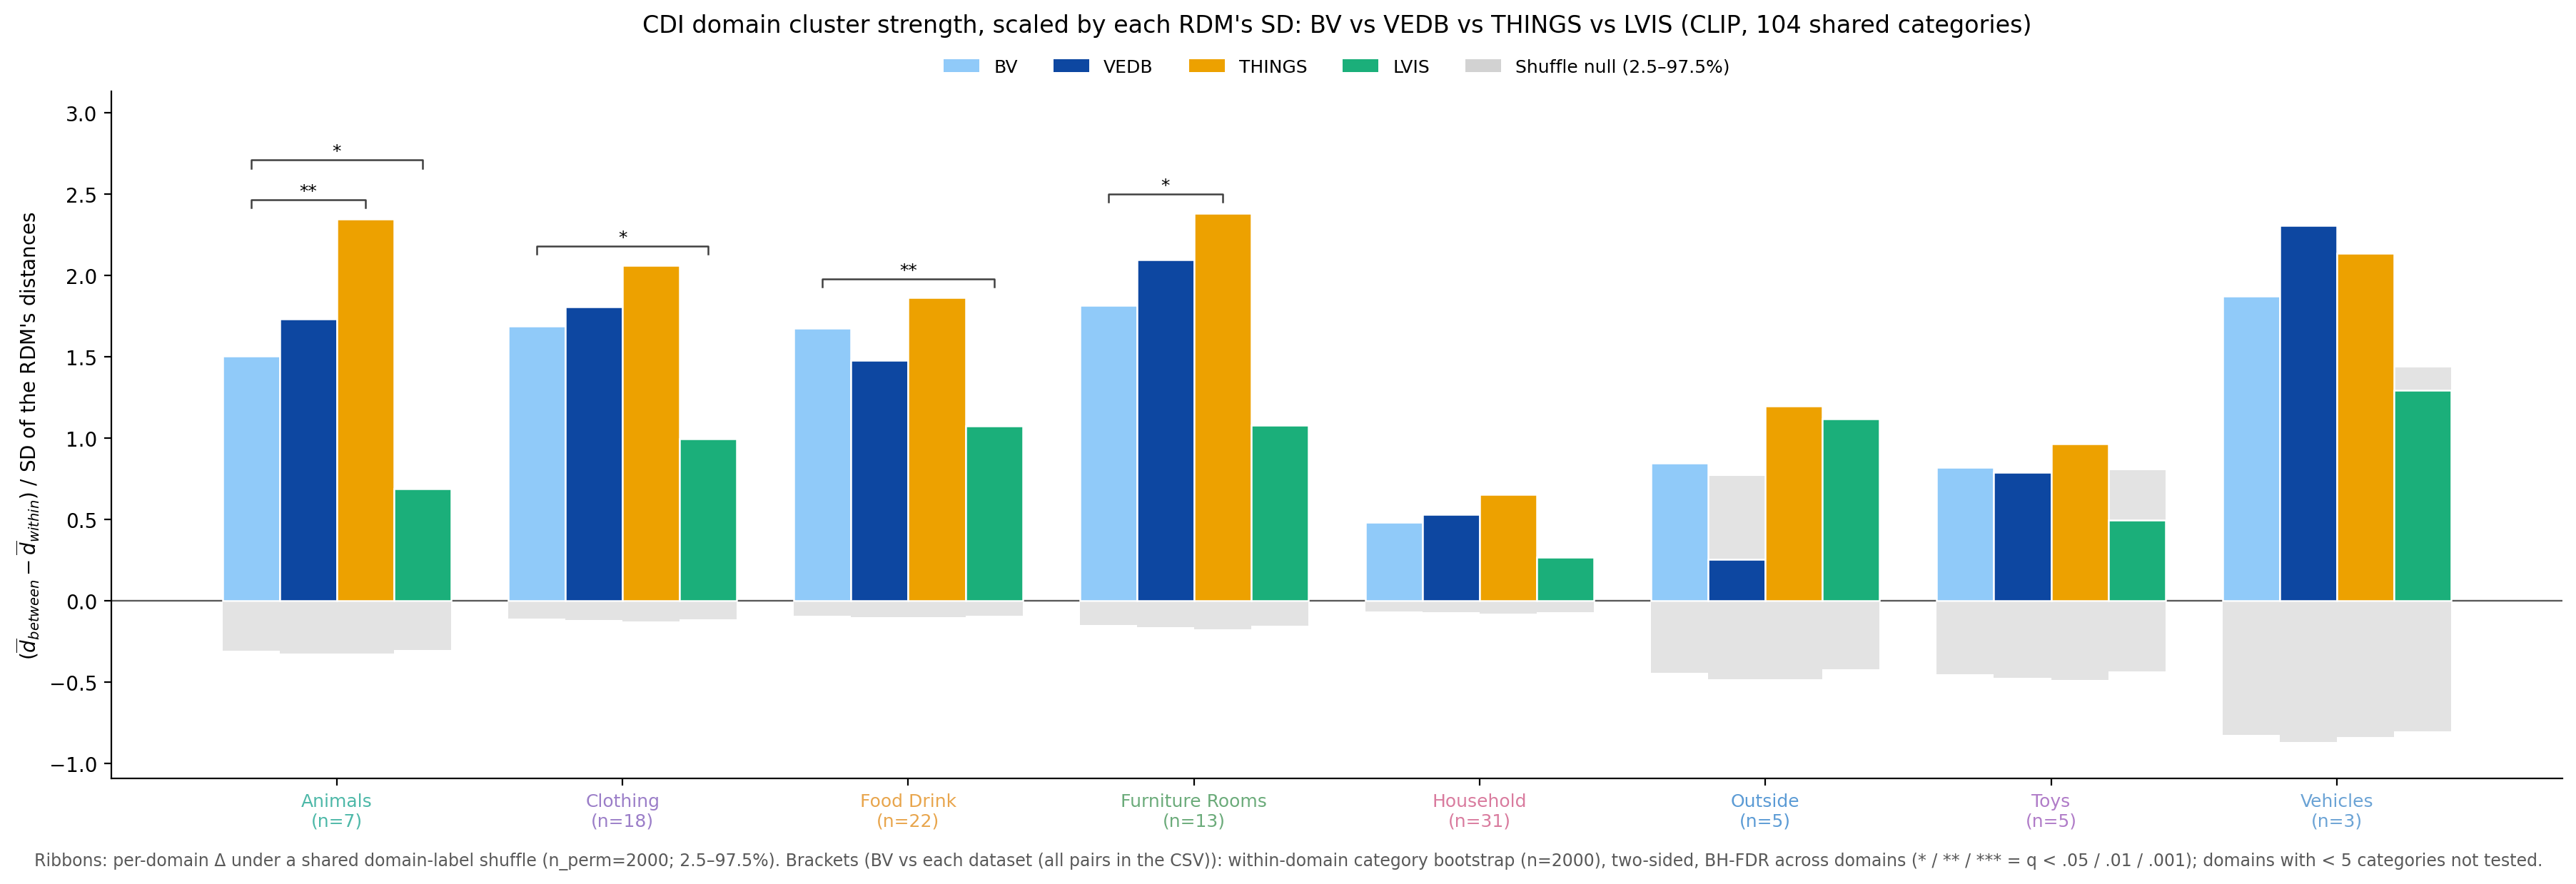

`outputs/cluster_strength/bv_vedb_things_lvis/figures/cluster_strength_bars_sdnorm_dinov3_bv_vedb_things_lvis.png`

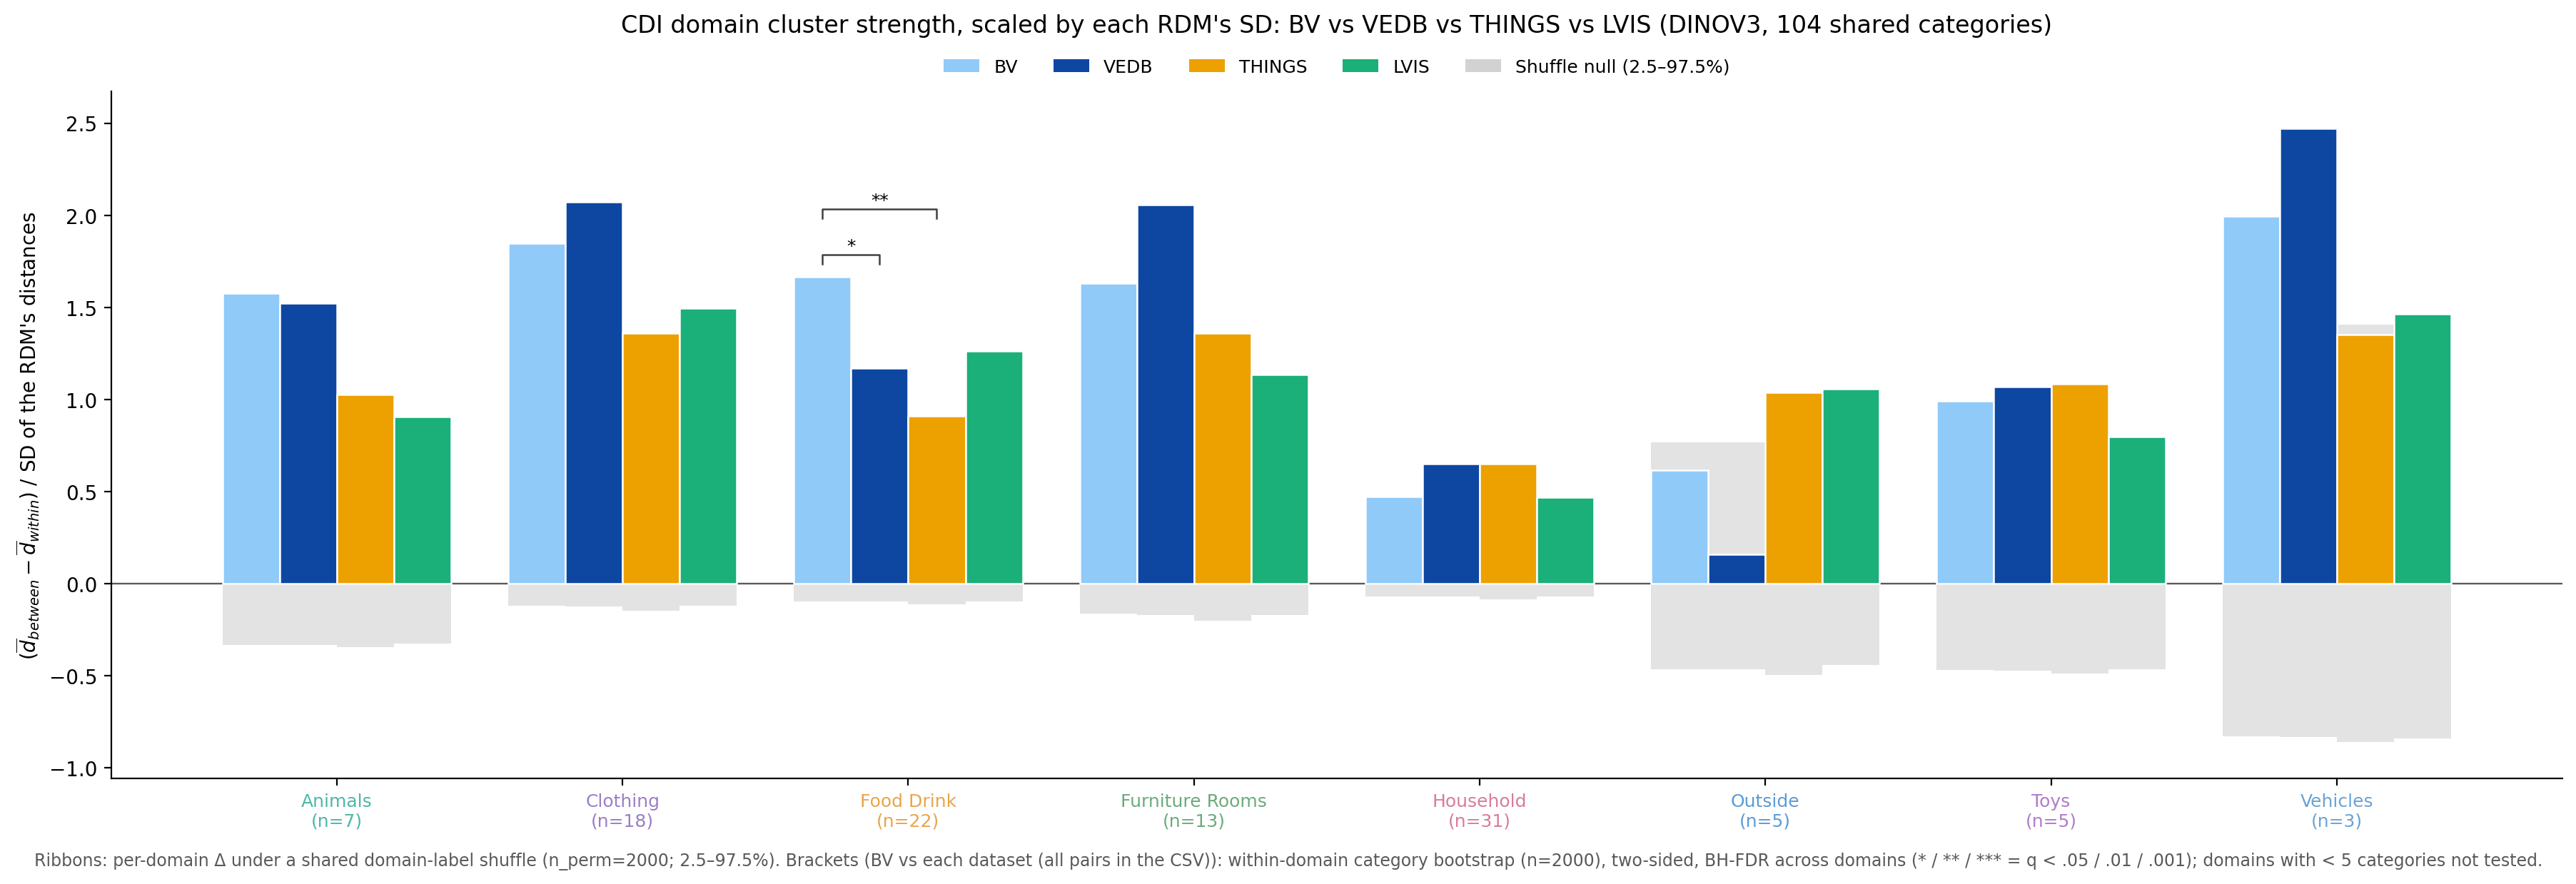

`outputs/cluster_strength/bv_vedb_things_lvis/figures/cluster_strength_bars_clip_bv_vedb_things_lvis.png`

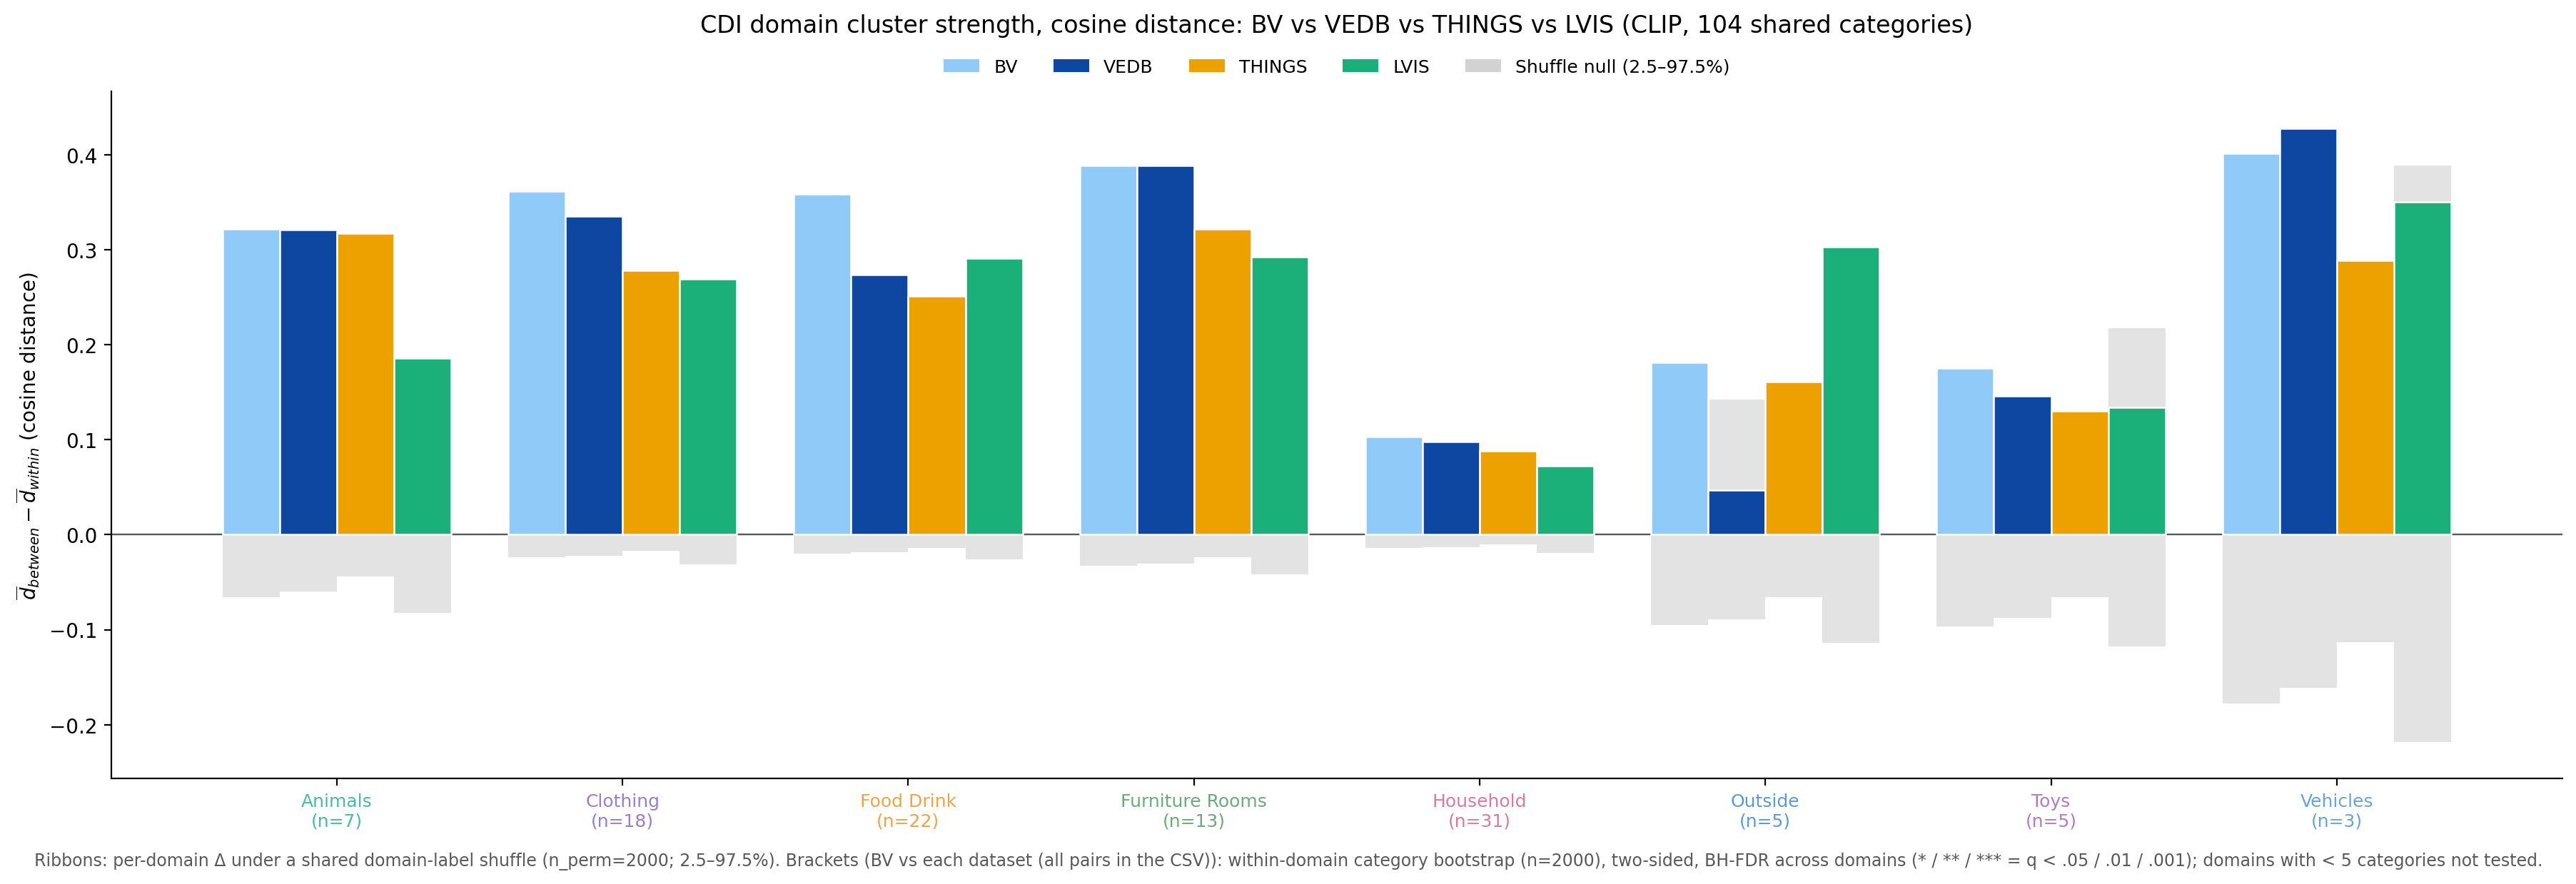

`outputs/cluster_strength/bv_vedb_things_lvis/figures/cluster_strength_bars_dinov3_bv_vedb_things_lvis.png`

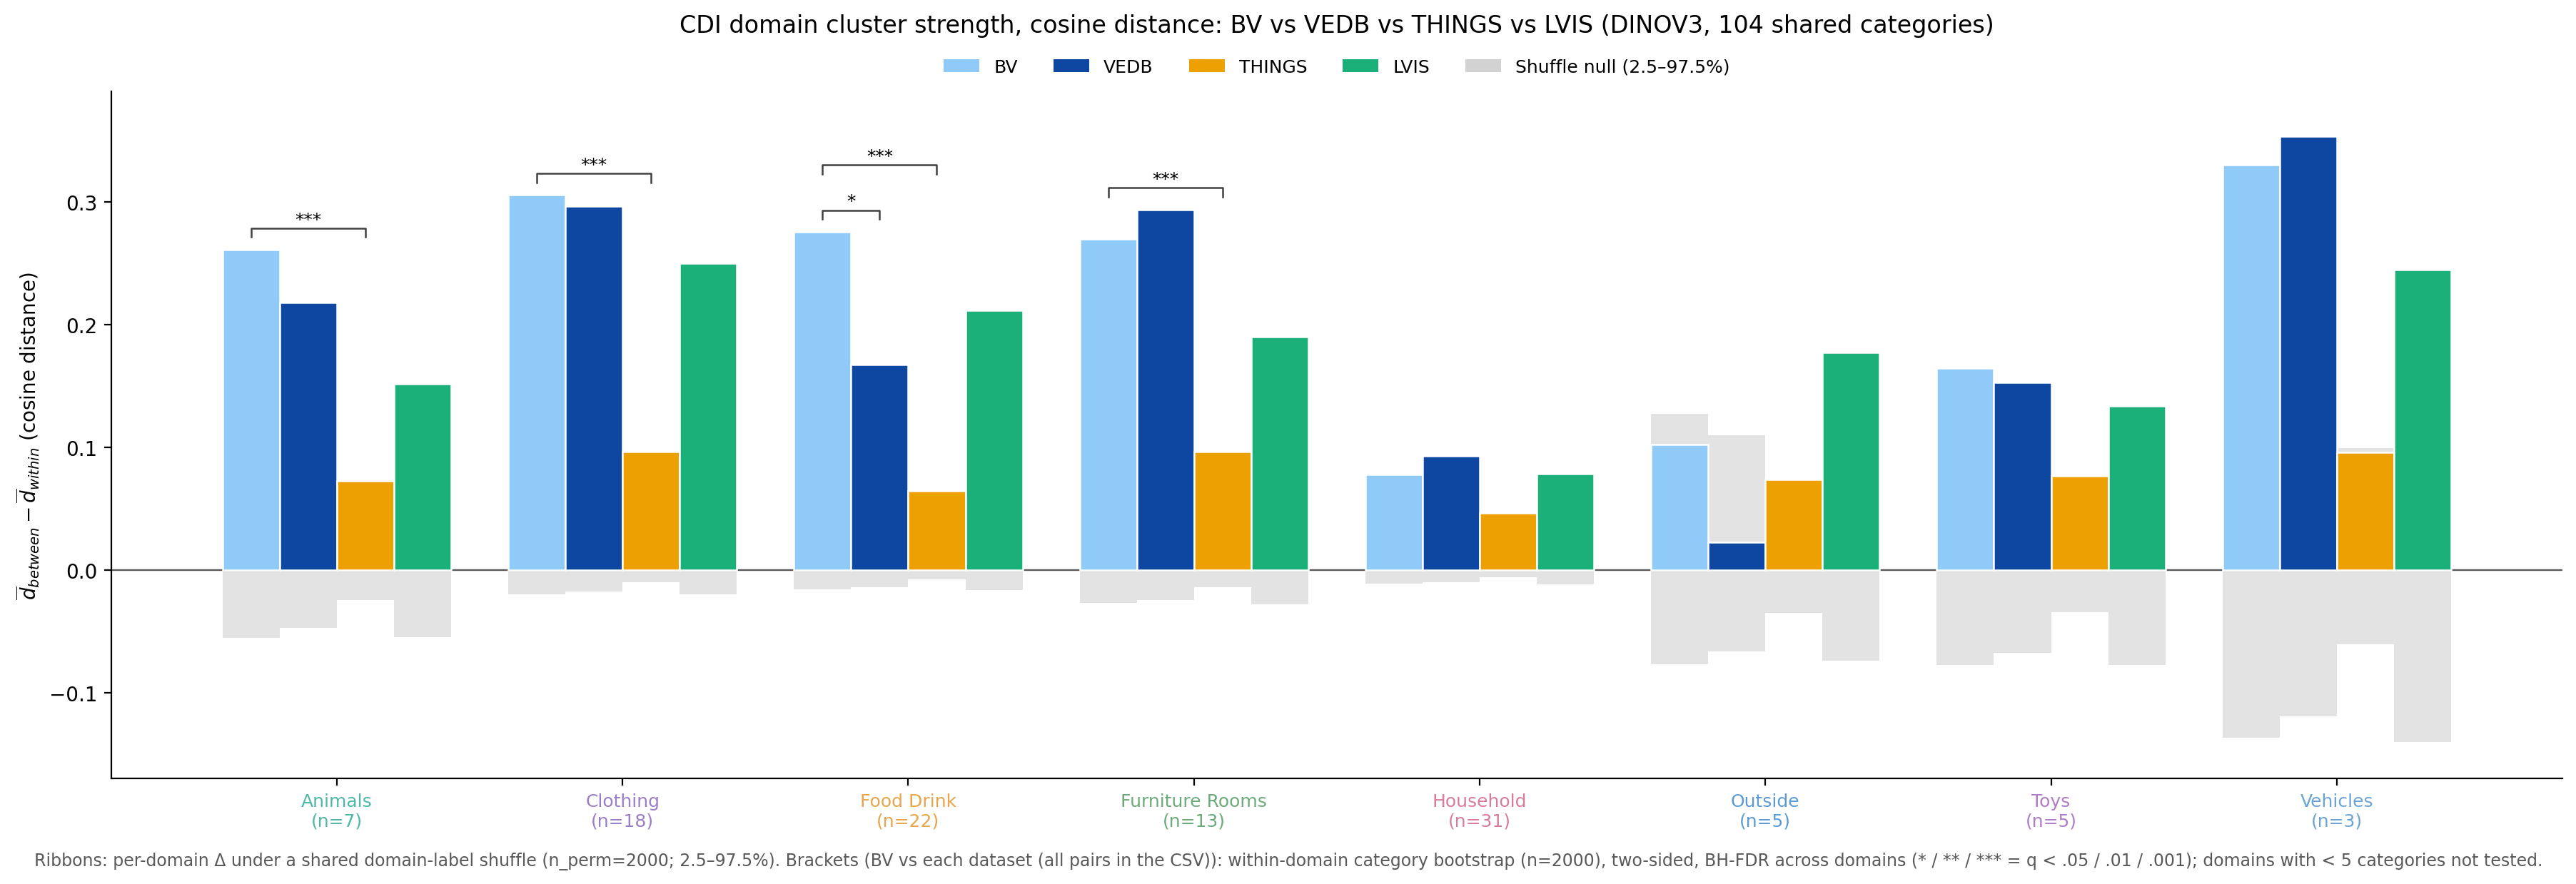

In [10]:
t = "_".join(DATASETS)
f = OUT / "cluster_strength" / t / "figures"
show_images([f / f"cluster_strength_bars_sdnorm_{m}_{t}.png" for m in MODELS] + [f / f"cluster_strength_bars_{m}_{t}.png" for m in MODELS])

### Review checklist

- Does the fast Δ match the reference (the assert in `analyze`)?
- Are bootstrap draws shared across datasets, with same-category pairs dropped?
- Which conclusions change between raw and scaled Δ?